# Impact of Principal Components and Encoded Features

Julian Hsu

2026oct15

The purpose of this script is to understand how to interpret the estimated impact of a the encoding of several features. For example, the principal component. 

We show how we need to use simulations to understand how an estimate of principal components. With principal components, we could backwards work the math easily because principal components are linear, but we use simulations as a more free-form approach to be agnostic of the encoding model.

## Motivation
Suppose the true DGP is:

$$ Y_i = \tau A_{i} + f(X_i, \beta) + e_i $$

Where $A_i$ is a $K x N$ matrix. Let's also assume that $\tau$ is only non-zero for one of those columns. 

But the actual regression we run is:

$$ Y_i = \pi PCA(A_i) + f(X_i, \gamma) + e_i $$

Where $PCA(A_i)$ are the principal components of $A_i$. We may run into this problem if $A_i$ is high dimensional, highly sparse, or just too complicated to throw into a single regression and estimate multiple $\tau$. 


In [25]:
import numpy as np
import pandas as pd

import statsmodels.api as sm

In [26]:
from sklearn.decomposition import PCA

## Primitives and functions

In [27]:
## Set hyperparameters
N = 1000
K = 10

np.random.seed = 624


In [ ]:
def dgp(N=None,K=None):
    ## Define the matrix A 
    ## Create correlations between the components of A
    ## With a covariance matrix that needs to be postivie semi-definite 
    # Create a random square matrix
    cov = np.random.uniform(0.5,0.8, size=(K, K))
    cov_symm = np.dot(cov, cov.T)

    A = np.random.multivariate_normal(np.zeros(K), 
                                      cov_symm , 
                                      size=(N))

    ## Let's also force the first column to be binary
    A[:,0] = (A[:,0] > 0.5).astype(float)
    A_coef = np.zeros(K)
    A_coef[0] = 2 

    ## Create confounders
    X1 = np.random.uniform(0,1, N)
    X2 = np.random.uniform(0,1, N)

    ## Create the baseline outcome 
    y_baseline = 1*X1 - 2*X2 + np.random.normal(0,0.5, N)

    y_obs = y_baseline + np.dot(A, A_coef)

    output_df = pd.DataFrame(data={'y':y_obs,
                                'y_baseline':y_baseline,
                                'x1':X1, 'x2':X2})
    for k in range(K):
        output_df['a_'+str(k)] = A[:,k]
    return output_df 

In [29]:
## Estimate OLS and make sure we can recover the true estimate as a sanity check

x=dgp(N,K)
display('Sanity check that the columns a are correlated')
display(x[[e for e in x.columns if 'a_' in e]].corr().round(2))


'Sanity check that the columns a are correlated'

,a_0,a_1,a_2,a_3,a_4,a_5,a_6,a_7,a_8,a_9
a_0,1.00,0.67,0.71,0.71,0.65,0.67,0.73,0.71,0.68,0.75
a_1,0.67,1.00,0.88,0.82,0.85,0.96,0.88,0.91,0.85,0.85
a_2,0.71,0.88,1.00,0.94,0.80,0.86,0.92,0.80,0.94,0.90
a_3,0.71,0.82,0.94,1.00,0.89,0.84,0.90,0.76,0.96,0.87
a_4,0.65,0.85,0.80,0.89,1.00,0.92,0.91,0.81,0.92,0.77
a_5,0.67,0.96,0.86,0.84,0.92,1.00,0.92,0.87,0.90,0.81
a_6,0.73,0.88,0.92,0.90,0.91,0.92,1.00,0.87,0.94,0.88
a_7,0.71,0.91,0.80,0.76,0.81,0.87,0.87,1.00,0.74,0.88
a_8,0.68,0.85,0.94,0.96,0.92,0.90,0.94,0.74,1.00,0.83
a_9,0.75,0.85,0.90,0.87,0.77,0.81,0.88,0.88,0.83,1.00


In [30]:


covariates = x[[e for e in x.columns if 'a_' in e] + ['x1','x2']]
res = sm.OLS(x['y'], sm.add_constant(covariates))
res_fit =  res.fit()

In [31]:
coef_a = res_fit.params['a_0'] 
se_a = res_fit.bse['a_0']  

ci05,ci95 = coef_a - 1.96*se_a, coef_a + 1.96*se_a

print('Coef: {0:5.2f}'.format(coef_a))

print('CI: {0:5.2f}, {1:5.2f}'.format(ci05, ci95))

Coef:  2.06
CI:  1.95,  2.16


## Encoding using PCA
Now let's encode the A matrix into something with fewer dimensions. We'll go with PCA for simplicity.

Then we will find the components to best explain the features.

In [32]:
AA = x[[e for e in x.columns if 'a_' in e]]

In [33]:
from sklearn.decomposition import PCA

## Do an elbow rule test:
factors = []
exp_var = []
for k in range(1,K):
    pca_model = PCA(n_components=k)
    pca_model.fit(AA)
    exp_var_ = pca_model.explained_variance_ratio_.sum()
    factors.append(k)
    exp_var.append(exp_var_)

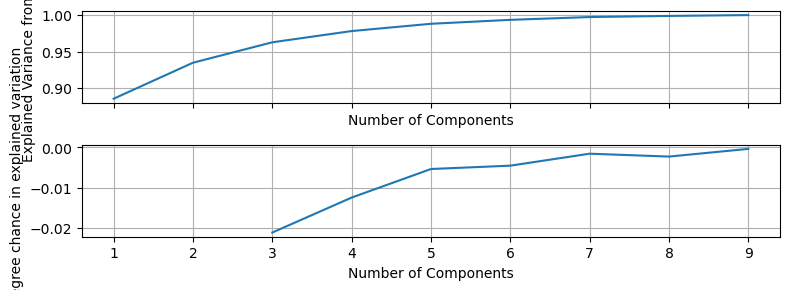

In [34]:
import matplotlib.pyplot as plt

fig,ax = plt.subplots(nrows=2, ncols=1, figsize=(8,3), sharex=True)
ax[0].plot(factors, exp_var)
ax[0].grid()
ax[0].set_xlabel('Number of Components')
ax[0].set_ylabel('Explained Variance from PCAs')

diff_exp_var = [exp_var[a+1] - exp_var[a] for a in range(len(exp_var)-1)]
diff_diff_exp_var = [diff_exp_var[a+1] - diff_exp_var[a] for a in range(len(diff_exp_var)-1)]


ax[1].plot(factors[2:], diff_diff_exp_var)
ax[1].grid()
ax[1].set_xlabel('Number of Components')
ax[1].set_ylabel('2nd degree chance in explained variation')

plt.tight_layout()





In [35]:
print('Let us go with half of the components'  )

Let us go with half of the components


In [36]:
magic_component_number = int(K/2.0)

pca_model = PCA(n_components=magic_component_number)
pca_model.fit(AA)


,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",5
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [37]:
pca_A = pca_model.fit_transform(X=AA)
print(pca_A.shape)
for r in range(magic_component_number):
    x['pcaA_'+str(r)] = pca_A[:,r]

print('show correlation with compoments and each other:')

display( x[[e for e in x.columns if 'a_' in e] + [p for p in x.columns if 'pcaA_' in p]].corr()[ [p for p in x.columns if 'pcaA_' in p]].round(2) )

(1000, 5)
show correlation with compoments and each other:


,pcaA_0,pcaA_1,pcaA_2,pcaA_3,pcaA_4
a_0,0.75,0.04,0.19,-0.16,0.01
a_1,0.94,0.25,-0.05,0.20,-0.08
a_2,0.95,-0.15,0.18,0.17,0.06
a_3,0.95,-0.27,0.07,-0.06,-0.13
a_4,0.93,-0.04,-0.30,-0.20,-0.08
a_5,0.95,0.14,-0.23,0.10,-0.01
a_6,0.97,-0.00,-0.03,-0.09,0.21
a_7,0.89,0.41,0.10,-0.12,-0.01
a_8,0.96,-0.25,-0.10,0.02,0.05
a_9,0.92,0.08,0.33,-0.07,-0.04


In [38]:
## Now fit an OLS on the principal components instead of the direct featurese


cov_pca = x[[e for e in x.columns if 'pcaA_' in e] + ['x1','x2']]
res = sm.OLS(x['y'], sm.add_constant(cov_pca))
res_fit =  res.fit()


display( res_fit.params[[e for e in x.columns if 'pcaA_' in e]] ) 
display( res_fit.bse[[e for e in x.columns if 'pcaA_' in e]]   )


pcaA_0    0.152057
pcaA_1    0.053159
pcaA_2    0.204841
pcaA_3   -0.262893
pcaA_4    0.003940
dtype: float64

pcaA_0    0.005377
pcaA_1    0.022847
pcaA_2    0.030397
pcaA_3    0.040891
pcaA_4    0.050845
dtype: float64

Okay so now we have estimates from an OLS model on the principal components instead of the underlying features. But it's impossible to interpret these because they run through the PCA? So what do we do?


Let's manually perturb the first underlying feature and then feed it back into the PCA and see what we get. Remember that the first feature is binary, so it's just a matter of comparing the output where:
* all are 0; and 
* all are 1. 

This will give us the average treatment effect. 




In [39]:
## Create two sets of principal components.
AA_0 = AA.copy()
AA_0['a_0'] = 0 
pca_A_0 = pca_model.transform(X=AA_0)

AA_1 = AA.copy()
AA_1['a_0'] = 1
pca_A_1  = pca_model.transform(X=AA_1)


## Compare the different principal components
for p in range(magic_component_number):
    cof = np.corrcoef(pca_A_0[:,p], pca_A_1[:,p])
    mean0 = pca_A_0[:,p].mean()
    mean1 = pca_A_1[:,p].mean()
    print( 'component {0}, {1:5.2f} vs {2:5.2f} and corr={3:5.3f}'.format(p, mean0, mean1, cof[0,1]) )

component 0, -0.03 vs  0.05 and corr=1.000
component 1, -0.01 vs  0.01 and corr=1.000
component 2, -0.04 vs  0.07 and corr=1.000
component 3,  0.05 vs -0.08 and corr=1.000
component 4, -0.00 vs  0.00 and corr=1.000


In [40]:
pca_A_0.shape

(1000, 5)

In [41]:
## Then get the predictions from the pertubations

pca_A_0_x = sm.add_constant( np.concatenate([pca_A_0, x[['x1','x2']]], axis=1)  ) 
x['y0_imp'] = res_fit.predict(exog=pca_A_0_x)


pca_A_1_x = sm.add_constant( np.concatenate([pca_A_1, x[['x1','x2']]], axis=1)  ) 
x['y1_imp'] = res_fit.predict(exog=pca_A_1_x)

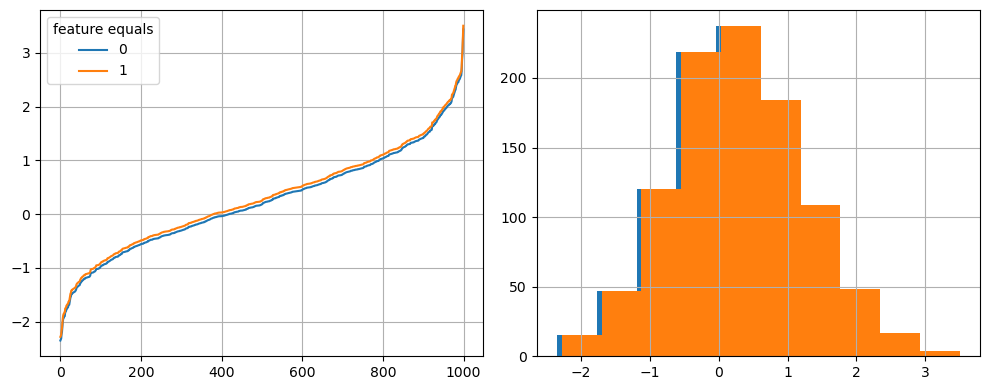

In [42]:
fig,ax = plt.subplots(ncols=2, nrows=1, figsize=(10,4))

## sort y0_imp in ascending order and then order y1_imp with the same index
x.sort_values(by='y0_imp', ascending=True, inplace=True)
ax[0].plot(np.arange(len(x)), x['y0_imp'], label='0')
ax[0].plot(np.arange(len(x)), x['y1_imp'], label='1')
ax[0].legend(title='feature equals')
ax[0].grid()

ax[1].hist(x['y0_imp'])
ax[1].hist(x['y1_imp'])
ax[1].grid()
plt.tight_layout()
plt.show()



Now, how do we get the standard error for this? We could directly use the delta method here, because we can directly tell how the principal components move when we shift the upstream factors. 

However, this ignores that the principal components themselves are model estimates. 

## Bootstrapping the standard error

Instead of the delta method, we bootstrap: resample the rows **with replacement** (so the same row can be drawn multiple times), and on each draw re-run the whole pipeline — estimate the PCA on the resampled `a_` columns, fit the OLS on the components + `x1`, `x2`, perturb the treated column to build `y0_imp` and `y1_imp`, and take their mean difference as the ATE for that draw. The spread of those ATEs across draws is the bootstrapped standard error, which accounts for the PCA itself being estimated.

In [43]:
## Bootstrap hyperparameters
B = 1000            ## number of bootstrap iterations
treated_column = 'a_0'

In [44]:
def resample_with_replacement(df=None):
    ## Draw N row indices with replacement, so the same row can appear multiple times
    draw_idx = np.random.randint(0, len(df), size=len(df))
    return df.iloc[draw_idx].reset_index(drop=True)


def estimate_pca(df=None, k=None):
    ## Estimate the PCA on the a_ columns of the (resampled) data, mirroring the PCA section above
    AA_boot = df[[e for e in df.columns if 'a_' in e]]
    pca_boot = PCA(n_components=k)
    pca_boot.fit(AA_boot)
    return pca_boot


def make_counterfactual_exog(df=None, pca_boot=None, k=None, set_value=None):
    ## Set the treated column to a single counterfactual value for everyone,
    ## run it through the *fitted* PCA, and return the model covariates
    AA_cf = df[[e for e in df.columns if 'a_' in e]].copy()
    AA_cf[treated_column] = set_value

    pca_cf = pca_boot.transform(X=AA_cf)

    pca_cf_x = np.concatenate([pca_cf, df[['x1','x2']]], axis=1)
    return sm.add_constant(pca_cf_x)


def bootstrap_ate_once(df=None, k=None):
    ## One bootstrap iteration: resample, estimate PCA, fit OLS, perturb, and
    ## compute the difference between y1_imp and y0_imp
    df_boot = resample_with_replacement(df)

    ## Fit the PCA on the resampled a_ columns
    pca_boot = estimate_pca(df_boot, k)

    ## Project the resampled a_ columns onto the fitted components
    AA_boot = df_boot[[e for e in df_boot.columns if 'a_' in e]]
    pca_A_boot = pca_boot.transform(X=AA_boot)

    ## Fit the outcome model on the components + confounders, mirroring the OLS section above
    pca_A_boot_x = sm.add_constant( np.concatenate([pca_A_boot, df_boot[['x1','x2']]], axis=1)  )
    res_boot = sm.OLS(df_boot['y'], pca_A_boot_x).fit()

    ## Counterfactual predictions with the treated column set to 0 and to 1
    exog_0 = make_counterfactual_exog(df_boot, pca_boot, k, set_value=0)
    exog_1 = make_counterfactual_exog(df_boot, pca_boot, k, set_value=1)

    y0_imp = res_boot.predict(exog=exog_0)
    y1_imp = res_boot.predict(exog=exog_1)

    return (y1_imp - y0_imp).mean()

In [45]:
ate_boot = []
for b in range(B):
    ate_boot.append(bootstrap_ate_once(x, magic_component_number))

ate_boot = np.array(ate_boot)

## Point estimate from the full sample, and the bootstrap standard error
ate_point = (x['y1_imp'] - x['y0_imp']).mean()
ate_se = ate_boot.std(ddof=1)   ## sample std over replicates (B-1 divisor), the unbiased bootstrap SE
ate_mc = ate_se / np.sqrt(2*B)  ## Monte Carlo error of the simulation itself: se/sqrt(2B)
display('Point estimate ATE: {0:.4f}'.format(ate_point))
display('Bootstrap mean ATE: {0:.4f}, std error: {1:.4f} (MC error +/-{2:.4f})'.format(ate_boot.mean(), ate_se, ate_mc))
display('95% percentile interval: [{0:.4f}, {1:.4f}]'.format(np.percentile(ate_boot, 2.5), np.percentile(ate_boot, 97.5)))

'Point estimate ATE: 0.0686'

'Bootstrap mean ATE: 0.0716, std error: 0.0124 (MC error +/-0.0003)'

'95% percentile interval: [0.0496, 0.0979]'

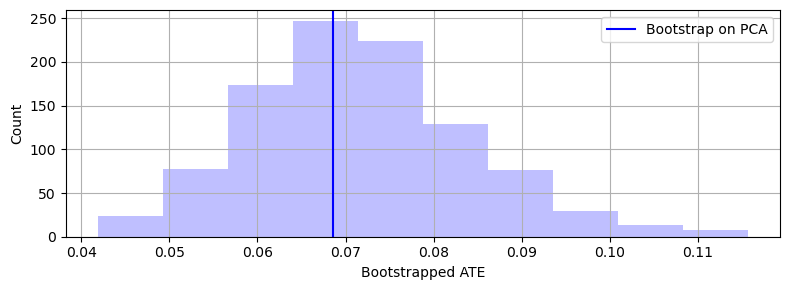

In [46]:
fig,ax = plt.subplots(figsize=(8,3))
ax.hist(ate_boot, color='blue', alpha=0.25)
ax.axvline(ate_point, color='blue', label='Bootstrap on PCA')
ax.set_xlabel('Bootstrapped ATE')
ax.set_ylabel('Count')
ax.legend()
ax.grid()
plt.tight_layout()
plt.show()





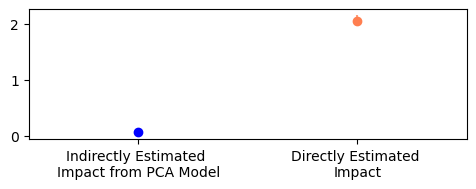

In [47]:
fig,ax = plt.subplots(figsize=(5,2))
ax.scatter(0, ate_point, color='blue')
ax.vlines(0, ate_point- 1.96*ate_se, ate_point+1.96*ate_se, color='blue',alpha=0.75)
ax.scatter(1, coef_a, color='coral')
ax.vlines(1, ci05, ci95, color='coral',alpha=0.75)
ax.set_xticks([0,1])
ax.set_xticklabels(['Indirectly Estimated \nImpact from PCA Model', 'Directly Estimated \nImpact'])
ax.set_xlim([-0.5,1.5])
plt.tight_layout()
plt.show()
